<a href="https://colab.research.google.com/github/sonalisankar/Netflix-Analysis-/blob/main/Netflix_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, mannwhitneyu

sns.set_theme(style="whitegrid")

df = pd.read_csv("netflix_titles.csv")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Rows and columns: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [2]:
# Dataset structure
df.info()

# Column names
print("Columns:")
print(df.columns.tolist())

# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Missing values
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

display(missing.sort_values(
    "Missing Percentage", ascending=False
))

# Summary statistics
display(df.describe(include="all").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB
Columns:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']
Duplicate rows: 0


,Missing Count,Missing Percentage
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03
show_id,0,0.00
type,0,0.00
title,0,0.00
release_year,0,0.00


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,8807,8807,s8807,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8807,2,Movie,6131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8807,8807,Zubaan,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,6173,4528,Rajiv Chilaka,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,7982,7692,David Attenborough,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,7976,748,United States,2818,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8797,1767,"January 1, 2020",109,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,8807.0,NaN,NaN,NaN,2014.180198,8.819312,1925.0,2013.0,2017.0,2019.0,2021.0
rating,8803,17,TV-MA,3207,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,8804,220,1 Season,1793,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
clean = df.copy()

# Standardize column names
clean.columns = [
    col.strip().lower().replace(" ", "_")
    for col in clean.columns
]

# Remove leading/trailing whitespace
for col in clean.select_dtypes(include="object").columns:
    clean[col] = clean[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Replace empty strings with missing values
clean = clean.replace("", np.nan)

# Remove exact duplicate rows
clean = clean.drop_duplicates()

# Ensure show IDs are unique
if "show_id" in clean.columns:
    clean = clean.drop_duplicates(
        subset=["show_id"], keep="first"
    )

# Fill missing categorical metadata
for col in ["director", "cast", "country", "rating", "duration"]:
    if col in clean.columns:
        clean[col] = clean[col].fillna("Unknown")

# Convert date fields
clean["date_added"] = pd.to_datetime(
    clean["date_added"], errors="coerce"
)

clean["release_year"] = pd.to_numeric(
    clean["release_year"], errors="coerce"
).astype("Int64")

# Extract numeric duration and its unit
clean["duration_value"] = pd.to_numeric(
    clean["duration"].astype(str).str.extract(r"(\d+)")[0],
    errors="coerce"
)

clean["duration_unit"] = (
    clean["duration"].astype(str)
    .str.extract(r"([A-Za-z]+)")[0]
    .str.lower()
)

clean.loc[
    clean["duration"].eq("Unknown"),
    ["duration_value", "duration_unit"]
] = [np.nan, "unknown"]

# Extract the primary genre
clean["primary_genre"] = (
    clean["listed_in"].astype(str)
    .str.split(",").str[0].str.strip()
)

# Extract the year Netflix added the title
clean["date_added_year"] = clean["date_added"].dt.year

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", clean.shape)

display(clean.head())

Original dataset shape: (8807, 12)
Cleaned dataset shape: (8807, 16)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,duration_value,duration_unit,primary_genre,date_added_year
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",90.0,min,Documentaries,2021.0
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2.0,seasons,International TV Shows,2021.0
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,1.0,season,Crime TV Shows,2021.0
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",1.0,season,Docuseries,2021.0
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2.0,seasons,International TV Shows,2021.0


,Number of Titles,Percentage
type,,
Movie,6131,69.62
TV Show,2676,30.38


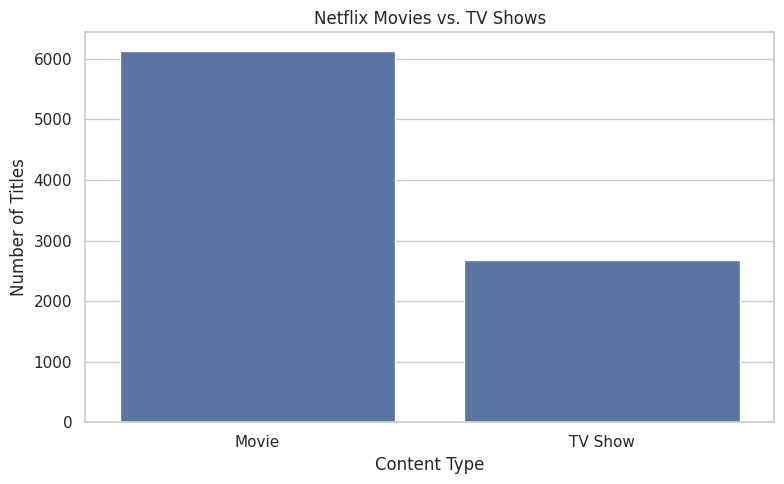

In [4]:
type_counts = clean["type"].value_counts()

type_summary = pd.DataFrame({
    "Number of Titles": type_counts,
    "Percentage": (
        type_counts / len(clean) * 100
    ).round(2)
})

display(type_summary)

# Bar chart
plt.figure(figsize=(8, 5))
sns.countplot(data=clean, x="type")

plt.title("Netflix Movies vs. TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()

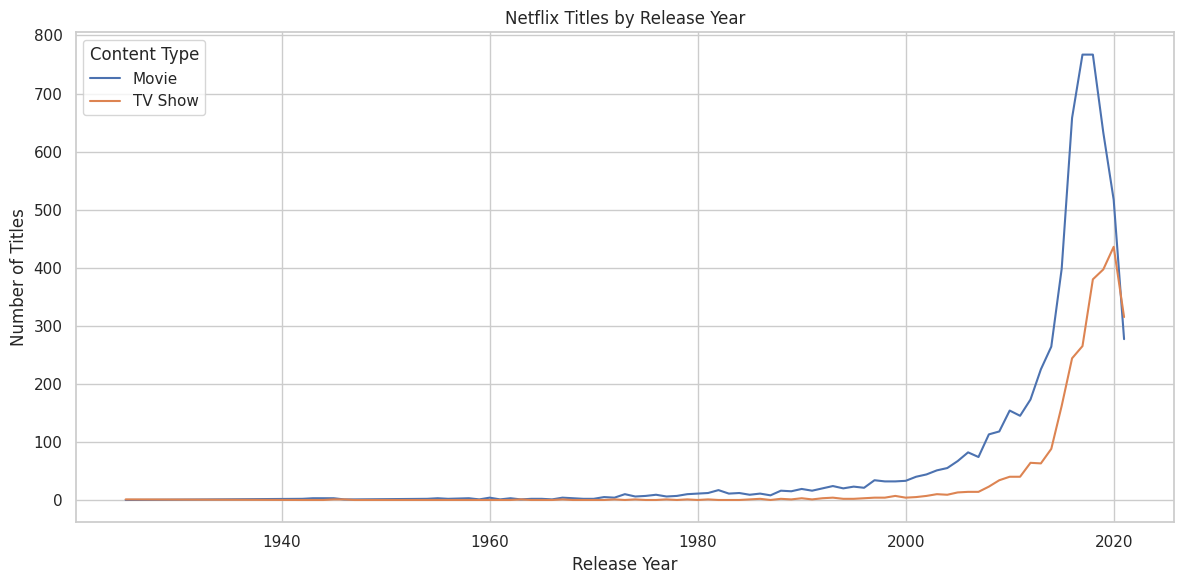

type,Movie,TV Show
release_year,,
2012,173,64
2013,225,63
2014,264,88
2015,398,162
2016,658,244
2017,767,265
2018,767,380
2019,633,397
2020,517,436


In [5]:
year_counts = (
    clean.dropna(subset=["release_year"])
    .groupby(["release_year", "type"])
    .size()
    .unstack(fill_value=0)
)

year_counts.plot(figsize=(12, 6))

plt.title("Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()

# Compare recent release years
display(year_counts.tail(10))

,Number of Titles
country,
United States,3689
India,1046
United Kingdom,804
Canada,445
France,393
Japan,318
Spain,232
South Korea,231
Germany,226


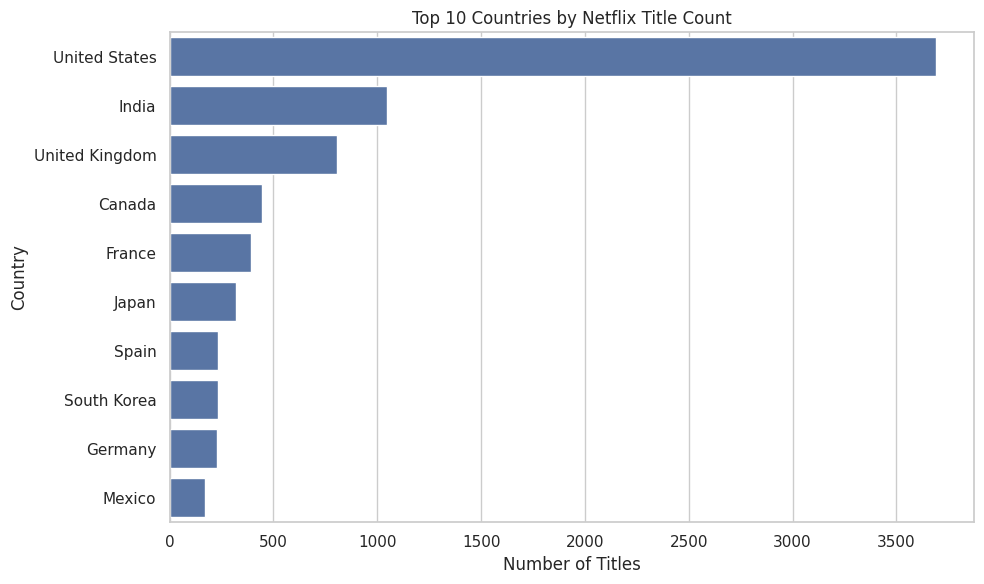

In [6]:
countries = (
    clean[clean["country"] != "Unknown"]
    .assign(country=lambda x: x["country"].str.split(", "))
    .explode("country")
)

top_countries = countries["country"].value_counts().head(10)

display(top_countries.to_frame("Number of Titles"))

plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title("Top 10 Countries by Netflix Title Count")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

,Title-Genre Count
genre,
International Movies,2752
Dramas,2427
Comedies,1674
International TV Shows,1351
Documentaries,869
Action & Adventure,859
TV Dramas,763
Independent Movies,756
Children & Family Movies,641


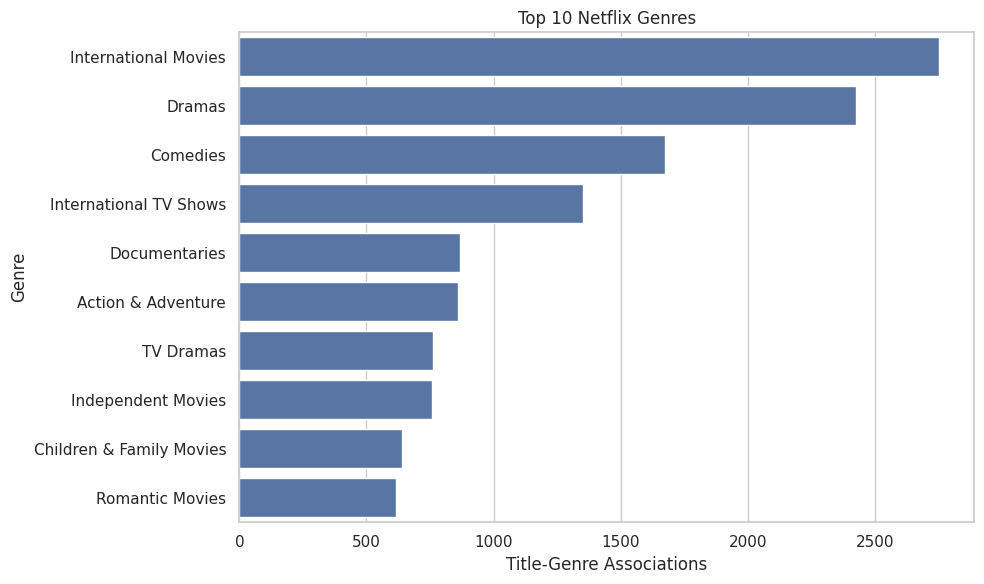

In [7]:
genres = (
    clean[clean["listed_in"].notna()]
    .assign(genre=lambda x: x["listed_in"].str.split(", "))
    .explode("genre")
)

top_genres = genres["genre"].value_counts().head(10)

display(top_genres.to_frame("Title-Genre Count"))

plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_genres.values,
    y=top_genres.index
)

plt.title("Top 10 Netflix Genres")
plt.xlabel("Title-Genre Associations")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

type,Movie,TV Show
rating,,
66 min,1,0
74 min,1,0
84 min,1,0
G,41,0
NC-17,3,0
NR,75,5
PG,287,0
PG-13,490,0
R,797,2


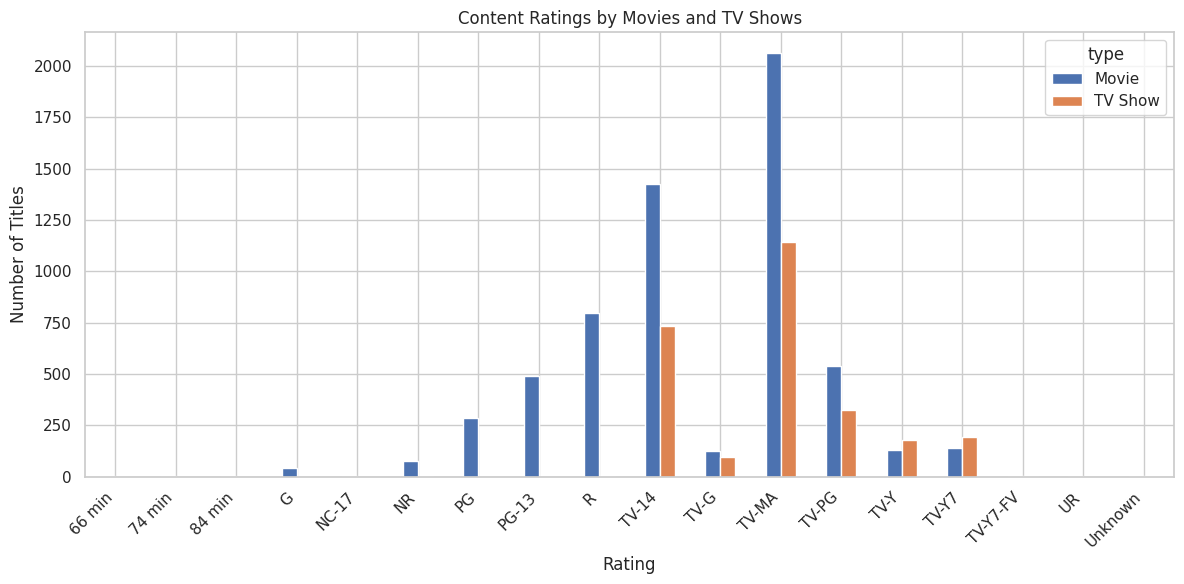

In [8]:
rating_counts = pd.crosstab(
    clean["rating"],
    clean["type"]
)

display(rating_counts)

rating_counts.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Content Ratings by Movies and TV Shows")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Movie runtime statistics:


,duration_value
count,6128.000000
mean,99.577187
std,28.290593
min,3.000000
25%,87.000000
50%,98.000000
75%,114.000000
max,312.000000


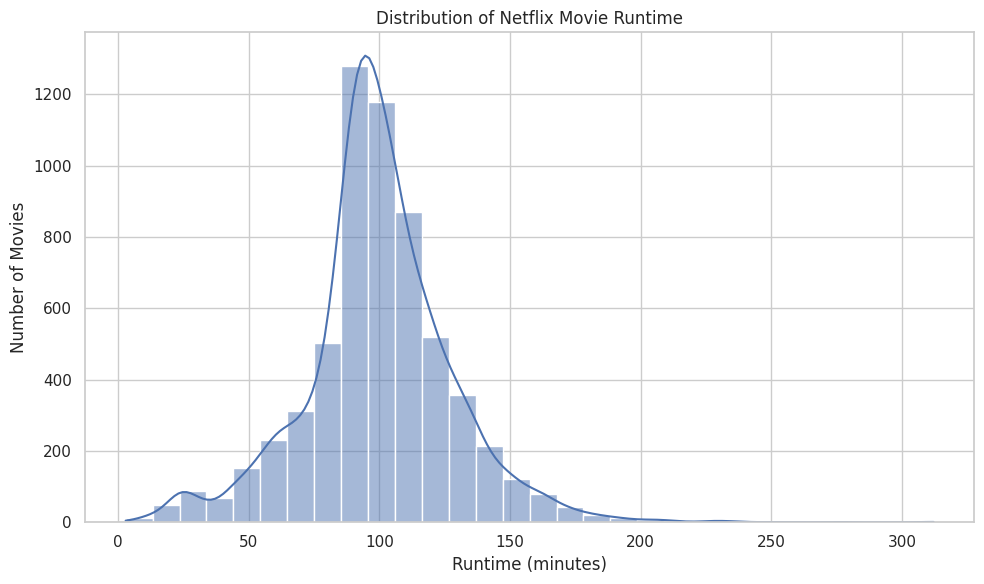

TV show season statistics:


,duration_value
count,1793.0
mean,1.0
std,0.0
min,1.0
25%,1.0
50%,1.0
75%,1.0
max,1.0


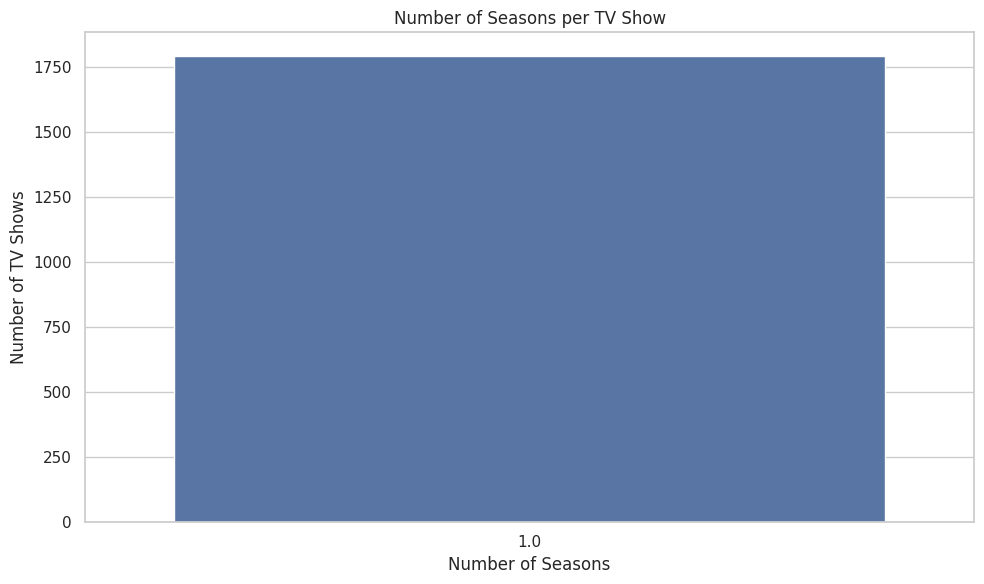

In [9]:
# Movie runtime analysis
movies = clean[
    (clean["type"] == "Movie") &
    (clean["duration_unit"] == "min")
].copy()

print("Movie runtime statistics:")
display(movies["duration_value"].describe())

plt.figure(figsize=(10, 6))
sns.histplot(
    data=movies,
    x="duration_value",
    bins=30,
    kde=True
)

plt.title("Distribution of Netflix Movie Runtime")
plt.xlabel("Runtime (minutes)")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

# TV show season analysis
tv_shows = clean[
    (clean["type"] == "TV Show") &
    (clean["duration_unit"] == "season")
].copy()

print("TV show season statistics:")
display(tv_shows["duration_value"].describe())

plt.figure(figsize=(10, 6))
sns.countplot(
    data=tv_shows,
    x="duration_value",
    order=sorted(tv_shows["duration_value"].dropna().unique())
)

plt.title("Number of Seasons per TV Show")
plt.xlabel("Number of Seasons")
plt.ylabel("Number of TV Shows")
plt.tight_layout()
plt.show()

,Number of Titles
director,
Rajiv Chilaka,22
Jan Suter,21
Raúl Campos,19
Suhas Kadav,16
Marcus Raboy,16
Jay Karas,15
Cathy Garcia-Molina,13
Martin Scorsese,12
Youssef Chahine,12


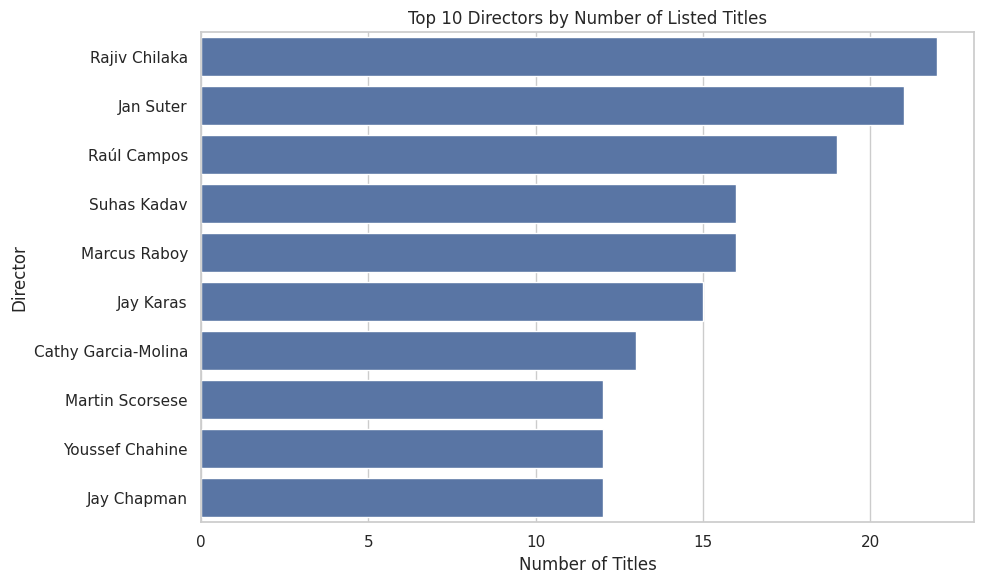

In [10]:
directors = (
    clean[clean["director"] != "Unknown"]
    .assign(director=lambda x: x["director"].str.split(", "))
    .explode("director")
)

top_directors = directors["director"].value_counts().head(10)

display(top_directors.to_frame("Number of Titles"))

plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_directors.values,
    y=top_directors.index
)

plt.title("Top 10 Directors by Number of Listed Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Director")
plt.tight_layout()
plt.show()

In [11]:
# Create a contingency table
rating_table = pd.crosstab(
    clean["type"],
    clean["rating"]
)

# Exclude Unknown ratings from the test
rating_table = rating_table.drop(
    columns=["Unknown"],
    errors="ignore"
)

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    rating_table
)

print("Chi-square statistic:", round(chi2, 4))
print("Degrees of freedom:", dof)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print(
        "Result: There is a statistically significant "
        "association between content type and rating."
    )
else:
    print(
        "Result: There is insufficient evidence of a "
        "statistically significant association."
    )

Chi-square statistic: 1047.6941
Degrees of freedom: 16
P-value: 6.822436324208583e-213
Result: There is a statistically significant association between content type and rating.


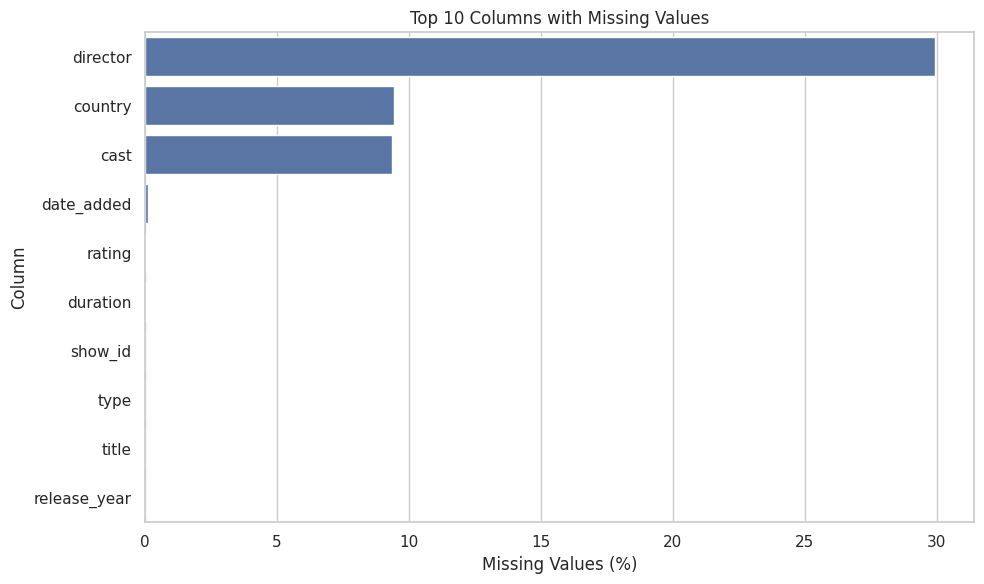

In [12]:
missing_percent = (
    df.isnull().mean() * 100
).sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=missing_percent.values,
    y=missing_percent.index
)

plt.title("Top 10 Columns with Missing Values")
plt.xlabel("Missing Values (%)")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

In [12]:
clean.to_csv(
    "netflix_titles_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [13]:
print("=" * 55)
print("NETFLIX DATA ANALYSIS: BUSINESS SUMMARY")
print("=" * 55)

print(f"\nTotal titles analyzed: {len(clean):,}")

print("\nContent distribution:")
for content_type, count in type_counts.items():
    percentage = count / len(clean) * 100
    print(
        f"{content_type}: {count:,} titles "
        f"({percentage:.2f}%)"
    )

print("\nTop 5 countries:")
print(top_countries.head(5))

print("\nTop 5 genres:")
print(top_genres.head(5))

print("\nTop 5 directors:")
print(top_directors.head(5))

print("\nMovie runtime:")
print(
    "Median runtime:",
    movies["duration_value"].median(),
    "minutes"
)

print("\nTV show seasons:")
print(
    "Median seasons:",
    tv_shows["duration_value"].median()
)

print("\nRating association test:")
print("Chi-square p-value:", round(p_value, 6))

print("\nBUSINESS CONSIDERATIONS")
print("1. Identify genres with strong catalog representation.")
print("2. Compare the mix of Movies and TV Shows over time.")
print("3. Review country representation for further research.")
print("4. Improve missing metadata where feasible.")
print(
    "5. Validate content investment decisions with "
    "viewership, retention, and cost data."
)

NETFLIX DATA ANALYSIS: BUSINESS SUMMARY

Total titles analyzed: 8,807

Content distribution:
Movie: 6,131 titles (69.62%)
TV Show: 2,676 titles (30.38%)

Top 5 countries:
country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Name: count, dtype: int64

Top 5 genres:
genre
International Movies      2752
Dramas                    2427
Comedies                  1674
International TV Shows    1351
Documentaries              869
Name: count, dtype: int64

Top 5 directors:
director
Rajiv Chilaka    22
Jan Suter        21
Raúl Campos      19
Suhas Kadav      16
Marcus Raboy     16
Name: count, dtype: int64

Movie runtime:
Median runtime: 98.0 minutes

TV show seasons:
Median seasons: 1.0

Rating association test:
Chi-square p-value: 0.0

BUSINESS CONSIDERATIONS
1. Identify genres with strong catalog representation.
2. Compare the mix of Movies and TV Shows over time.
3. Review country representation for further research.
4. I

# Netflix Movies and TV Shows Data Analysis Using Python

## Project Overview
This project analyzes the Netflix Movies and TV Shows dataset using Python in Google Colab. The goal is to explore Netflix's content library, identify patterns and trends, examine content distribution, and generate meaningful insights through data cleaning, exploratory data analysis (EDA), statistical analysis, and data visualization.

## Project Objectives
- Clean and prepare the Netflix dataset for analysis.
- Identify missing values and duplicate records.
- Analyze the distribution of movies and TV shows.
- Explore content by country, genre, rating, and release year.
- Examine trends in Netflix content additions over time.
- Use statistical analysis to investigate relationships between content type and ratings.
- Develop data-driven insights and recommendations based on the findings.

## Tools and Technologies
- **Python** — Programming language for data analysis.
- **Google Colab** — Cloud-based environment used to write and execute Python code.
- **Pandas and NumPy** — Data cleaning, manipulation, and analysis.
- **Matplotlib and Seaborn** — Data visualization.
- **SciPy** — Statistical hypothesis testing.

## Project Methodology

### 1. Data Loading
Imported the Netflix Movies and TV Shows dataset into Google Colab using Pandas.

### 2. Data Cleaning and Preprocessing
- Inspected the dataset's structure, data types, and missing values.
- Checked for duplicate records.
- Handled missing values where appropriate.
- Standardized relevant columns and prepared the data for analysis.

### 3. Exploratory Data Analysis (EDA)
Analyzed the dataset to understand:
- The proportion of movies compared with TV shows.
- Content distribution across countries and genres.
- Ratings and release-year patterns.
- Movie runtimes and TV show durations.
- Trends in the years content was added to Netflix.

### 4. Data Visualization
Created charts using Matplotlib and Seaborn to communicate findings clearly and identify patterns in the Netflix catalog.

### 5. Statistical Analysis
Used a chi-square test of independence to examine whether content type (movie or TV show) and rating category were associated.

### 6. Insights and Recommendations
Interpreted the results to identify content distribution patterns, data quality limitations, and opportunities for further analysis.

## Key Findings
- Movies represented approximately **69.6%** of the 8,807 titles, while TV shows represented approximately **30.4%**.
- The median runtime of movies was **98 minutes**.
- The United States had the largest number of country-associated titles, followed by India and the United Kingdom.
- International Movies, Dramas, and Comedies were among the most frequently listed genres.
- TV-MA and TV-14 were the most common rating categories.
- The year 2019 had the highest number of titles added to Netflix in the dataset.
- The chi-square test indicated a statistically significant association between content type and rating category.

## Business Recommendations
- Analyze content categories alongside audience viewing data to better understand demand.
- Examine content release years separately from Netflix addition dates to distinguish production trends from catalog expansion.
- Improve metadata completeness, particularly for director, country, and cast information.
- Combine catalog data with viewership, engagement, retention, and cost data for more comprehensive business decisions.

## Conclusion
This project demonstrates how Python in Google Colab can be used to clean, analyze, visualize, and interpret a real-world entertainment dataset. It strengthened my skills in data preprocessing, exploratory data analysis, statistical testing, and communicating findings through visualizations.

**Limitation:** The dataset describes Netflix catalog metadata, not actual viewership, revenue, or profitability. Therefore, the number of titles in a category should not be interpreted as a direct measure of popularity or business success.